In [1]:
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval maite-datasets
except Exception:
    pass

In [2]:
import numpy as np
import polars as pl
from dataeval_plots import plot
from IPython.display import display
from maite_datasets.object_detection import VOCDetection

from dataeval import Metadata

# Load the classes from DataEval that are helpful for EDA
from dataeval.config import set_max_processes
from dataeval.core import image_stats, label_stats
from dataeval.flags import ImageStats
from dataeval.quality import Duplicates, Outliers

# Print all rows of dataframes
_ = pl.Config.set_tbl_rows(-1)

# Set the random value
rng = np.random.default_rng(213)

# Set multiprocessing for DataEval stats
set_max_processes(4)

In [3]:
# Helper method to plot sample images by class
def plot_sample_images_by_class(dataset, image_indices_per_class) -> None:
    import matplotlib.pyplot as plt

    # Plot random images from each category
    _, axs = plt.subplots(5, 4, figsize=(8, 10))

    for ax, (category, indices) in zip(axs.flat, image_indices_per_class.items(), strict=False):
        # Randomly select an index from the list of indices
        ax.imshow(dataset[rng.choice(indices)][0].transpose(1, 2, 0))
        ax.set_title(dataset.metadata["index2label"][category])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Helper method to plot images of interest
def plot_sample_outlier_images_by_metric(dataset, outlier_result, metric, layout) -> None:
    import matplotlib.gridspec as gridspec
    import matplotlib.pyplot as plt
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    # Filter outliers DataFrame for the specific metric
    metric_outliers = outlier_result.data().filter(pl.col("metric_name") == metric)

    if metric_outliers.is_empty():
        print(f"No images flagged for metric: {metric}")
        return

    # Get all metric values from stored calculation results to understand the distribution
    all_metric_values = outlier_result.calculation_results["stats"][metric]
    quantiles = np.quantile(all_metric_values, [0, 0.25, 0.5, 0.75, 1])
    median = quantiles[2]

    # Compute distance from median and sort by most extreme first
    ranked = (
        metric_outliers
        .unique(subset=["item_index"])
        .with_columns((pl.col("metric_value") - median).abs().alias("_distance"))
        .sort("_distance", descending=True)
        .drop("_distance")
    )

    # Determine number of samples to plot
    n_samples = min(int(np.prod(layout)), ranked.height)

    # Create figure with space for colorbar
    fig = plt.figure(figsize=(12, layout[0] * 4))
    gs = gridspec.GridSpec(
        layout[0],
        layout[1] + 1,
        width_ratios=[1] * layout[1] + [0.05],
        hspace=0.4,
        wspace=0.1,
        left=0.05,
        right=0.92,
        top=0.92,
        bottom=0.02,
    )

    # Create colormap normalization based on full metric distribution
    vmin, vmax = quantiles[0], quantiles[4]
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap("viridis")

    # Plot images
    for i in range(n_samples):
        row = ranked.row(i, named=True)
        img_id = row["item_index"]
        metric_value = row["metric_value"]
        color = cmap(norm(metric_value))

        ax = fig.add_subplot(gs[i // layout[1], i % layout[1]])
        ax.imshow(dataset[img_id][0].transpose(1, 2, 0))
        ax.set_xlabel(f"index: {img_id}\n{metric}: {np.round(metric_value, 3)}", fontsize=9, color="black")
        ax.set_xticks([])
        ax.set_yticks([])

        # Add colored border to indicate extremeness
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(5)
            spine.set_visible(True)

    # Add colorbar with quantile markers
    cbar_ax = fig.add_subplot(gs[:, -1])
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, cax=cbar_ax)
    cbar.set_ticks([])

    quantile_labels = ["Min (Q0)", "Q1 (25%)", "Median (Q2)", "Q3 (75%)", "Max (Q4)"]
    for q_val, q_label in zip(quantiles, quantile_labels, strict=False):
        cbar.ax.axhline(q_val, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
        cbar.ax.text(
            1.5,
            q_val,
            f"{q_label}\n{np.round(q_val, 2)}",
            va="center",
            fontsize=8,
            transform=cbar.ax.get_yaxis_transform(),
        )

    fig.suptitle(f'Outlier Images for "{metric}" (sorted by distance from median)', fontsize=12, y=0.99)
    plt.show()

In [4]:
# Download the data and then load it as a torch Tensor
ds = VOCDetection("./data", image_set="train", year="2012", download=True)
print(ds)

VOCDetection Dataset
--------------------
    Year: 2012
    Transforms: []
    Image Set: train
    Metadata: {'id': 'VOCDetection_train', 'index2label': {0: 'aeroplane', 1: 'bicycle', 2: 'bird', 3: 'boat', 4: 'bottle', 5: 'bus', 6: 'car', 7: 'cat', 8: 'chair', 9: 'cow', 10: 'diningtable', 11: 'dog', 12: 'horse', 13: 'motorbike', 14: 'person', 15: 'pottedplant', 16: 'sheep', 17: 'sofa', 18: 'train', 19: 'tvmonitor'}, 'split': 'train'}
    Path: /builds/jatic/aria/dataeval/docs/source/notebooks/data/vocdataset/VOCdevkit/VOC2012
    Size: 5717


In [5]:
# Create the Metadata object
md = Metadata(ds)

lstats = label_stats(md.class_labels, md.item_indices, ds.index2label, image_count=len(ds))

# View per_class data as a DataFrame
pl.DataFrame({
    "class_name": list(ds.index2label.values()),
    "label_count": [lstats["label_counts_per_class"][k] for k in ds.index2label],
    "image_count": [lstats["image_counts_per_class"][k] for k in ds.index2label],
})

/tmp/ipykernel_6763/921567072.py:4: UserWarning: `filename` and `mask_path` were dropped: nearly every row holds a different value, so the column identifies rows rather than grouping them, and it is not numeric so there is no order along which to cut it into groups. Map the values onto a smaller vocabulary to keep the factor. See Metadata.dropped_factors.
  lstats = label_stats(md.class_labels, md.item_indices, ds.index2label, image_count=len(ds))


class_name,label_count,image_count
str,i64,i64
"""aeroplane""",470,328
"""bicycle""",410,281
"""bird""",592,399
"""boat""",508,264
"""bottle""",749,399
"""bus""",317,219
"""car""",1191,621
"""cat""",609,540
"""chair""",1457,656


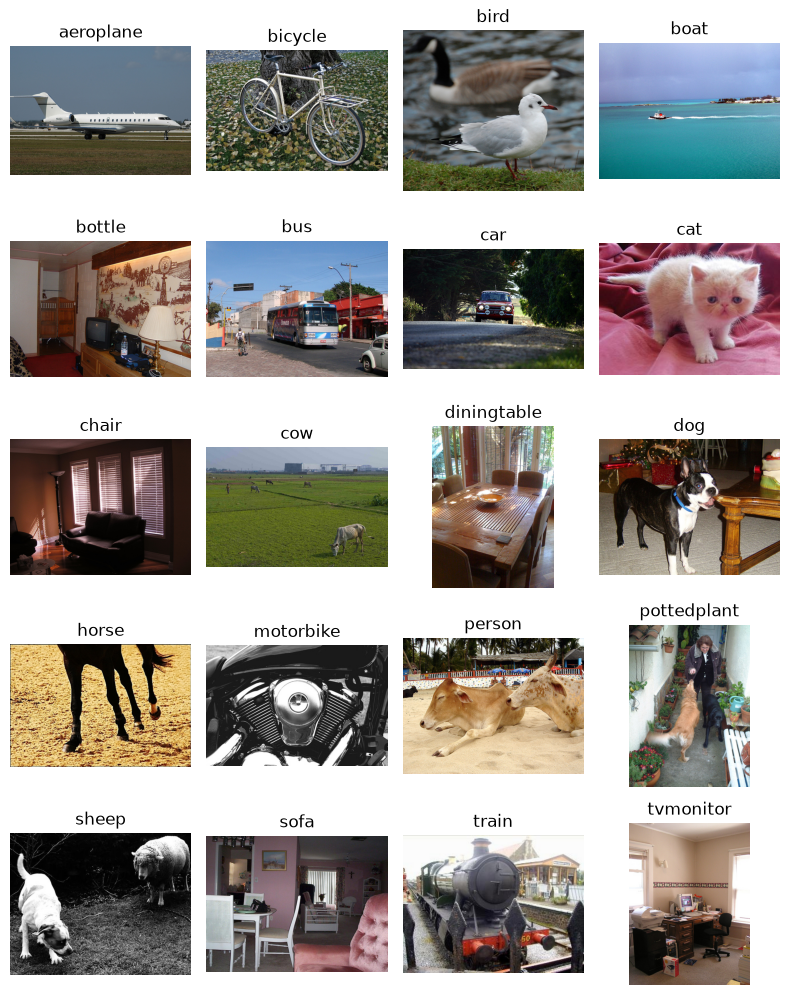

In [6]:
plot_sample_images_by_class(ds, lstats["image_indices_per_class"])

In [7]:
# This cell takes about 1-5 minutes to run depending on your hardware

# Initialize the Outliers class
outliers = Outliers(outlier_threshold="zscore")

# Find the extreme images
outlier_imgs = outliers.evaluate(ds, per_target=False)

# View the number of extreme images
print(f"Number of images with extreme values: {len(outlier_imgs)}")

Number of images with extreme values: 498


/tmp/ipykernel_6763/2880708496.py:7: UserWarning: `filename` and `mask_path` were dropped: nearly every row holds a different value, so the column identifies rows rather than grouping them, and it is not numeric so there is no order along which to cut it into groups. Map the values onto a smaller vocabulary to keep the factor. See Metadata.dropped_factors.
  outlier_imgs = outliers.evaluate(ds, per_target=False)


In [8]:
# List the metrics with an extreme value
outlier_imgs.aggregate_by_metric()

metric_name,Total
cat,u32
"""size""",173
"""entropy""",124
"""zeros""",100
"""contrast""",92
"""skew""",89
"""kurtosis""",73
"""brightness""",52
"""width""",43
"""var""",35


In [9]:
# List the outliers by class label
outlier_imgs.aggregate_by_class(md)

class_name,aspect_ratio,brightness,contrast,darkness,entropy,height,kurtosis,mean,sharpness,size,skew,std,var,width,zeros,Total
cat,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""person""",2,7,51,10,36,2,24,9,0,61,27,1,7,18,41,296
"""aeroplane""",0,22,4,2,28,5,23,7,0,12,30,6,1,1,2,143
"""bottle""",3,2,15,5,10,0,8,3,0,10,8,1,3,6,10,84
"""bird""",0,8,3,1,16,1,12,1,0,10,14,5,0,1,9,81
"""cat""",0,2,10,1,5,3,3,1,0,24,2,3,9,4,11,78
"""chair""",0,4,8,2,9,1,5,3,0,13,5,0,1,3,12,66
"""dog""",0,3,4,0,8,2,1,2,1,23,2,3,2,7,6,64
"""car""",0,0,7,2,6,3,2,1,0,18,1,0,3,3,7,53
"""boat""",0,2,2,1,6,4,2,1,0,8,3,2,0,0,1,32


In [10]:
# Fit the thresholds within each class instead of across the whole dataset
outlier_imgs_classwise = outlier_imgs.classwise(md)

print(f"Number of images flagged globally  : {len(outlier_imgs)}")
print(f"Number of images flagged per class : {len(outlier_imgs_classwise)}")

Number of images flagged globally  : 498
Number of images flagged per class : 568


In [11]:
# TEST ASSERTION CELL ###
# Verify the class counts that the text reads from the label statistics table
objects = {ds.index2label[k]: lstats["label_counts_per_class"][k] for k in ds.index2label}
images = {ds.index2label[k]: lstats["image_counts_per_class"][k] for k in ds.index2label}
assert 5000 < len(ds) < 6000
assert len(objects) == 20
assert sorted(objects, key=lambda name: -objects[name])[:3] == ["person", "chair", "car"]
assert sorted(images, key=lambda name: -images[name])[:3] == ["person", "chair", "dog"]
assert sorted(objects, key=lambda name: objects[name])[:3] == ["bus", "train", "cow"]
assert sorted(images, key=lambda name: images[name])[:3] == ["cow", "sheep", "bus"]

assert len(outlier_imgs_classwise) != len(outlier_imgs)
assert not outlier_imgs_classwise.populations["judged"].all()

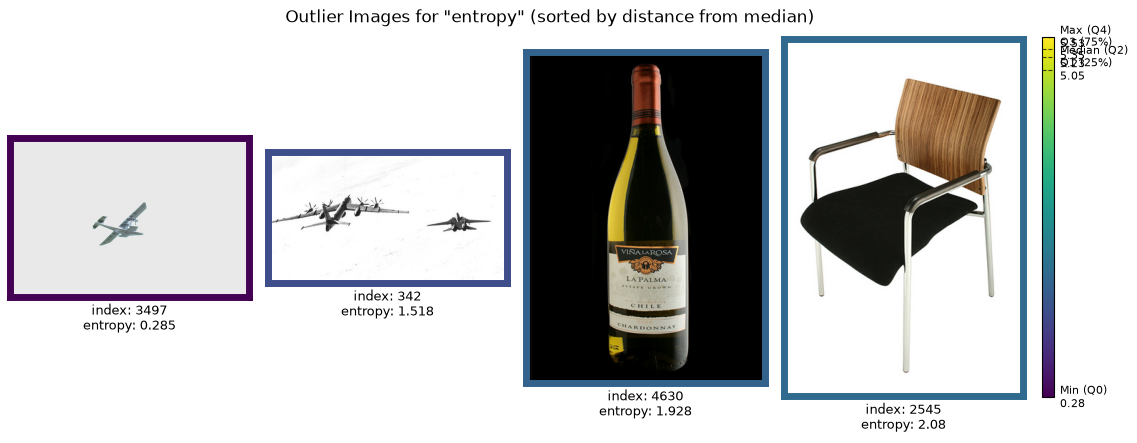

In [12]:
# Plot images flagged for "entropy"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "entropy", (1, 4))

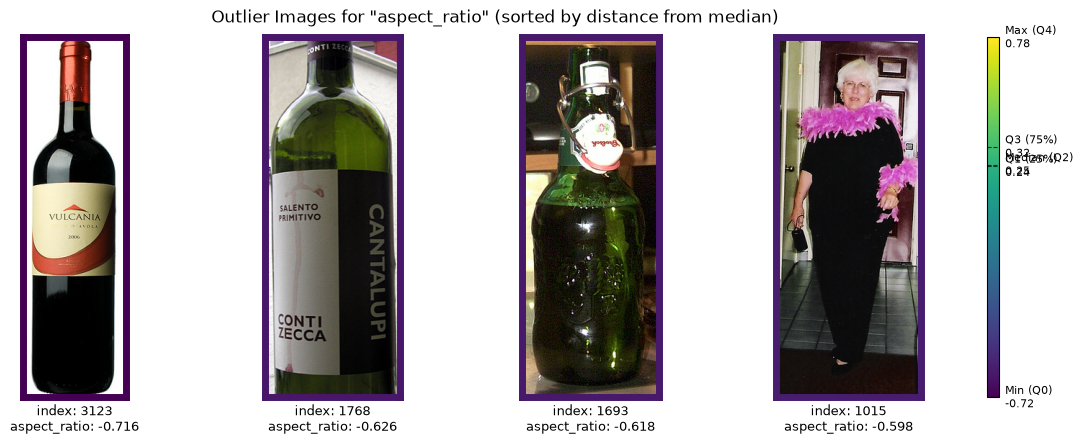

In [13]:
# Plot images flagged for "aspect_ratio"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "aspect_ratio", (1, 4))

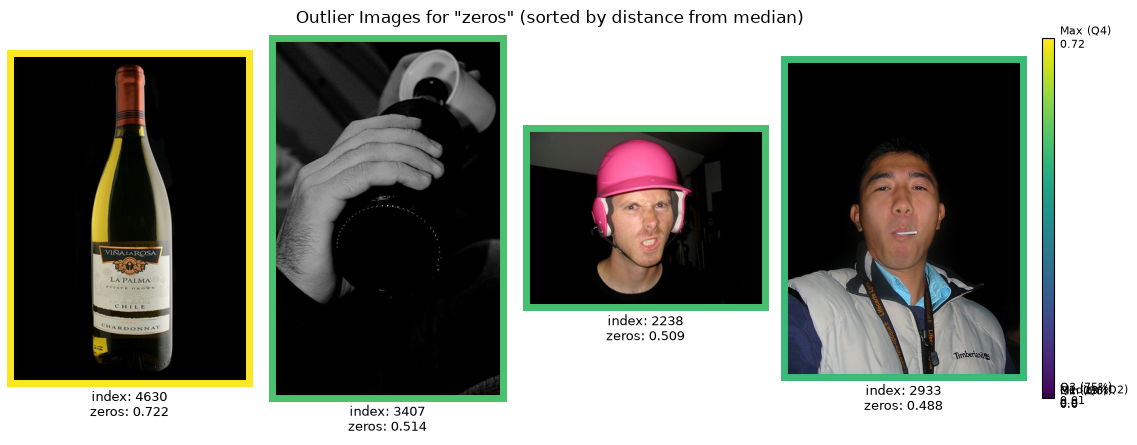

In [14]:
# Plot images flagged for "zeros"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "zeros", (1, 4))

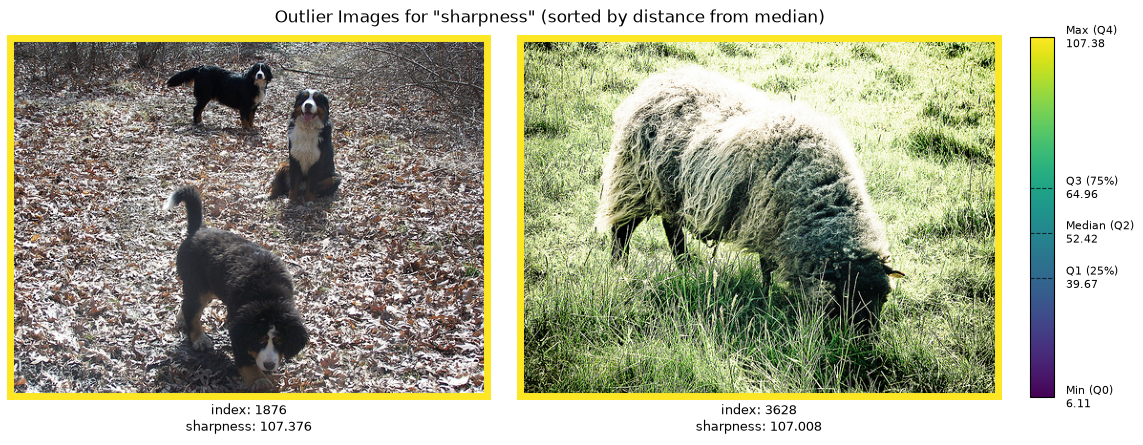

In [15]:
# Plot images flagged for "sharpness"
plot_sample_outlier_images_by_metric(ds, outlier_imgs, "sharpness", (1, 2))

In [16]:
# Initialize the Duplicates class
dups = Duplicates(ImageStats.HASH)

# Find the duplicates
results = dups.evaluate(ds, per_target=False)

/builds/jatic/aria/dataeval/src/dataeval/types/_output.py:359: FutureWarning: The default value of hash_radius will change from 0 in a future major release, so that Duplicates finds the perceptual near-duplicates it documents rather than only bit-identical ones (5 of 64 bits is the expected value). Pass hash_radius explicitly to pin the current behavior and silence this warning.
  result = fn(*args, **kwargs)


In [17]:
# View duplicate groups
display(results)

shape: (10, 8)
┌──────────┬───────┬────────────┬─────────────┬─────────────┬────────────┬────────────┬────────────┐
│ group_id ┆ level ┆ dup_type   ┆ item_indice ┆ methods     ┆ orientatio ┆ differs_on ┆ annotation │
│ ---      ┆ ---   ┆ ---        ┆ s           ┆ ---         ┆ n          ┆ ---        ┆ _divergenc │
│ i64      ┆ str   ┆ str        ┆ ---         ┆ list[str]   ┆ ---        ┆ list[str]  ┆ e          │
│          ┆       ┆            ┆ list[i64]   ┆             ┆ str        ┆            ┆ ---        │
│          ┆       ┆            ┆             ┆             ┆            ┆            ┆ f64        │
╞══════════╪═══════╪════════════╪═════════════╪═════════════╪════════════╪════════════╪════════════╡
│ 0        ┆ item  ┆ near       ┆ [1548,      ┆ ["dhash",   ┆ same       ┆ ["annotati ┆ 1.0        │
│          ┆       ┆            ┆ 1561]       ┆ "dhash_d4", ┆            ┆ on"]       ┆            │
│          ┆       ┆            ┆             ┆ … "phash…   ┆            ┆  

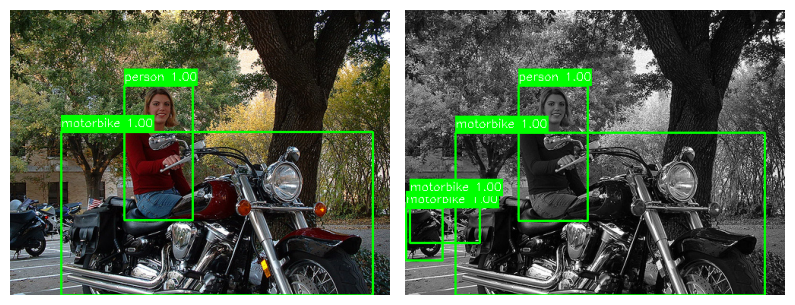

In [18]:
plot(ds, figsize=(12, 6), indices=(1548, 1561))

In [19]:
# Create exact and duplicate images

# Copy images 23 and 46 to create exact duplicates
# Copy and crop images 5 and 4376 to create near duplicates
# Rotate image 100 by 90 degrees to create a rotated duplicate
# Mirror and rotate image 200 to create a mirrored+rotated duplicate
dupes = [
    ds[23][0],  # exact duplicate
    ds[46][0],  # exact duplicate
    ds[5][0][:, 2:-2, 2:-2],  # cropped near duplicate
    ds[4376][0][:, :-5, 5:],  # cropped near duplicate
    np.rot90(ds[100][0], k=1, axes=(1, 2)),  # 90° rotation
    np.flip(np.rot90(ds[200][0], k=2, axes=(1, 2)), axis=2),  # 180° rotation + horizontal flip
]

dupes_stats = image_stats(dupes, stats=ImageStats.HASH)

In [20]:
# Find the duplicates appended to the dataset
duplicates = dups.from_stats([dups.stats, dupes_stats])

# View all duplicate groups
display(duplicates)

shape: (7, 9)
┌──────────┬───────┬──────────┬────────────┬───┬────────────┬────────────┬────────────┬────────────┐
│ group_id ┆ level ┆ dup_type ┆ item_indic ┆ … ┆ methods    ┆ orientatio ┆ differs_on ┆ annotation │
│ ---      ┆ ---   ┆ ---      ┆ es         ┆   ┆ ---        ┆ n          ┆ ---        ┆ _divergenc │
│ i64      ┆ str   ┆ str      ┆ ---        ┆   ┆ list[str]  ┆ ---        ┆ list[str]  ┆ e          │
│          ┆       ┆          ┆ list[i64]  ┆   ┆            ┆ str        ┆            ┆ ---        │
│          ┆       ┆          ┆            ┆   ┆            ┆            ┆            ┆ f64        │
╞══════════╪═══════╪══════════╪════════════╪═══╪════════════╪════════════╪════════════╪════════════╡
│ 0        ┆ item  ┆ exact    ┆ [23, 0]    ┆ … ┆ ["xxhash"] ┆ null       ┆ null       ┆ null       │
│ 1        ┆ item  ┆ exact    ┆ [46, 1]    ┆ … ┆ ["xxhash"] ┆ null       ┆ null       ┆ null       │
│ 2        ┆ item  ┆ near     ┆ [5, 2]     ┆ … ┆ ["phash",  ┆ same       ┆ nu